In [1]:
import tensorflow as tf
import pandas as pd
import numpy as np

In [2]:
path = r"C:\Users\Dell\Downloads\creditcard.csv"
df = pd.read_csv(path)
df

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


In [3]:
df = df.drop(['Time','Class'], axis=1)
df

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,4.356170,...,1.475829,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77
284803,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,-0.975926,...,0.059616,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79
284804,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,-0.484782,...,0.001396,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88
284805,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,-0.399126,...,0.127434,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00


In [4]:
# Preprocess the data
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

x_train, x_test = train_test_split(df, test_size=0.2)

In [5]:
print(x_train.shape[1])
print(x_test.shape[1])
type(x_train)

29
29


pandas.core.frame.DataFrame

In [6]:
from keras.models import Model, Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras import layers, models

In [7]:
encoder = tf.keras.models.Sequential([
    layers.Input(shape=(x_train.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(20, activation='relu')
])
        
decoder = tf.keras.models.Sequential([
    layers.Input(shape=(20,)),
    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(x_train.shape[1], activation='linear')  # Use linear activation for reconstruction
])
        
model = tf.keras.models.Sequential([
    encoder,
    decoder
])

In [8]:
model.compile(optimizer='adam', loss ='mean_squared_error')

In [9]:
history = model.fit(
    x_train, 
    x_train, 
    validation_data=(x_test,x_test),
    epochs=5,
    batch_size = 100,
    shuffle=True
)

Epoch 1/5
2279/2279 ━━━━━━━━━━━━━━━━━━━━ 18s 6ms/step - loss: 23.2542 - val_loss: 0.6414
Epoch 2/5
2279/2279 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - loss: 8.2372 - val_loss: 0.5252
Epoch 3/5
2279/2279 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - loss: 4.4518 - val_loss: 0.3496
Epoch 4/5
2279/2279 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - loss: 0.6630 - val_loss: 1.2321
Epoch 5/5
2279/2279 ━━━━━━━━━━━━━━━━━━━━ 14s 6ms/step - loss: 3.3586 - val_loss: 0.7852


<Axes: >

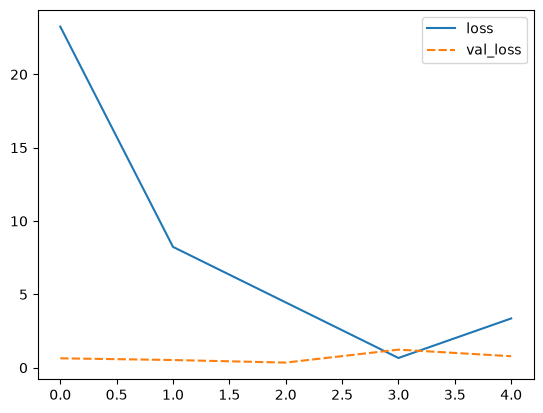

In [10]:
import seaborn as sns
sns.lineplot(model.history.history)

### Reconstruction error

For each transaction, reconstruction error is the mean squared difference between the original input and the autoencoder's reconstruction:

\[
RE_i = \frac{1}{p}\sum_{j=1}^{p}(x_{ij}-\hat{x}_{ij})^2
\]

A larger value means the autoencoder reconstructed that transaction less accurately. The threshold below flags transactions whose reconstruction error exceeds the selected percentile.

In [11]:
# Calculate reconstruction error (mean squared error) for each transaction
predictions = model.predict(x_test, verbose=0)

x_test_array = x_test.to_numpy()
reconstruction_error = np.mean(
    np.square(x_test_array - predictions),
    axis=1
)

print("First 10 reconstruction errors:")
print(reconstruction_error[:10])

First 10 reconstruction errors:
[0.11943133 0.0625324  0.50597876 0.07578353 0.17715381 0.19663597
 0.14706066 0.07517192 0.318123   0.43056405]


In [22]:
# Set the anomaly threshold using the 95th percentile of reconstruction errors
threshold = np.percentile(reconstruction_error, 95)
print("Reconstruction error threshold:", threshold)

Reconstruction error threshold: 2.1241827904661514


In [23]:
anomalies = reconstruction_error > threshold

In [24]:
# Calculate the number of transactions flagged as anomalies
num_anomalies = np.sum(anomalies)
print(f"Number of Anomalies: {num_anomalies}")

Number of Anomalies: 2849


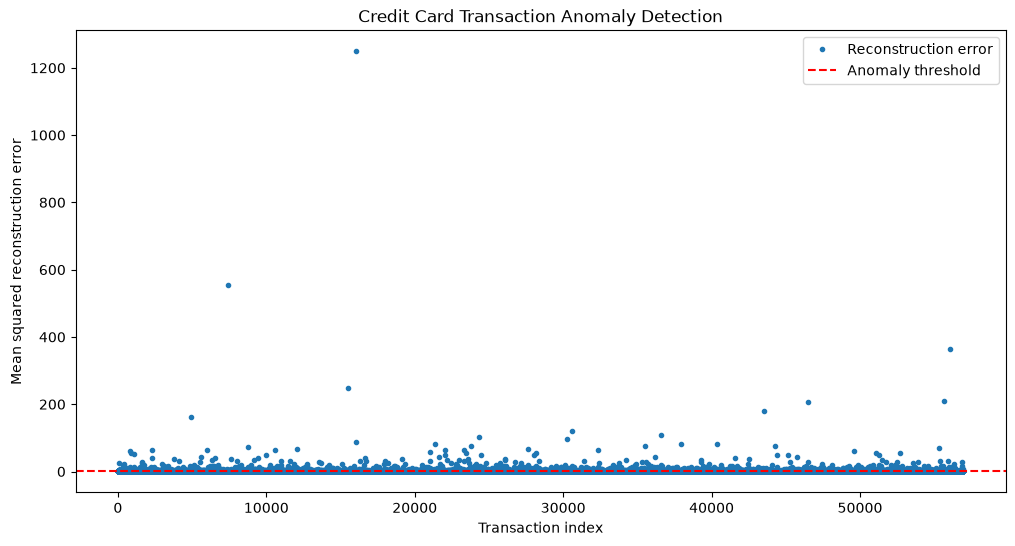

In [25]:
# Plot reconstruction errors and the anomaly threshold
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(reconstruction_error, marker='o', linestyle='', markersize=3,
         label='Reconstruction error')
plt.axhline(threshold, color='r', linestyle='--',
            label='Anomaly threshold')
plt.xlabel('Transaction index')
plt.ylabel('Mean squared reconstruction error')
plt.title('Credit Card Transaction Anomaly Detection')
plt.legend()
plt.show()